<a href="https://colab.research.google.com/github/Nik2416/Time-Series/blob/main/TS_STATIONARY_TEST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q statsmodels


In [ ]:
from statsmodels.tsa.stattools import adfuller

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Download American Airlines (AAL) stock data
df = yf.download("AAPL", start="2015-01-01", end="2026-01-01")

df.head()

/tmp/ipykernel_2054/1289353211.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("AAPL", start="2015-01-01", end="2026-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.171755,24.638255,23.733996,24.627199,212818400
2015-01-05,23.490799,24.021415,23.305084,23.941822,257142000
2015-01-06,23.493008,23.751682,23.132630,23.554913,263188400
2015-01-07,23.822432,23.921921,23.590287,23.700831,160423600
2015-01-08,24.737747,24.795231,24.032470,24.149649,237458000


In [ ]:
close = df["Close"].squeeze().dropna()

result = adfuller(close)

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])

if result[1] <= 0.05:
    print("Closing price is stationary")
else:
    print("Closing price is non-stationary")

ADF Statistic: 0.6592975418900302
p-value: 0.9889895775599007
Critical Values: {'1%': np.float64(-3.432725827000873), '5%': np.float64(-2.862589670460055), '10%': np.float64(-2.5673287729948187)}
Closing price is non-stationary


/tmp/ipykernel_2054/1736894567.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(close)


In [ ]:
df["Close_diff"] = close.diff()

stationary_data = df["Close_diff"].dropna()

result_diff = adfuller(stationary_data)

print("ADF Statistic after differencing:", result_diff[0])
print("p-value after differencing:", result_diff[1])

if result_diff[1] <= 0.05:
    print("Differenced data is stationary")
else:
    print("Differenced data is non-stationary")

ADF Statistic after differencing: -18.26469020047187
p-value after differencing: 2.3268553828898186e-30
Differenced data is stationary


/tmp/ipykernel_2054/1178661552.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(stationary_data)


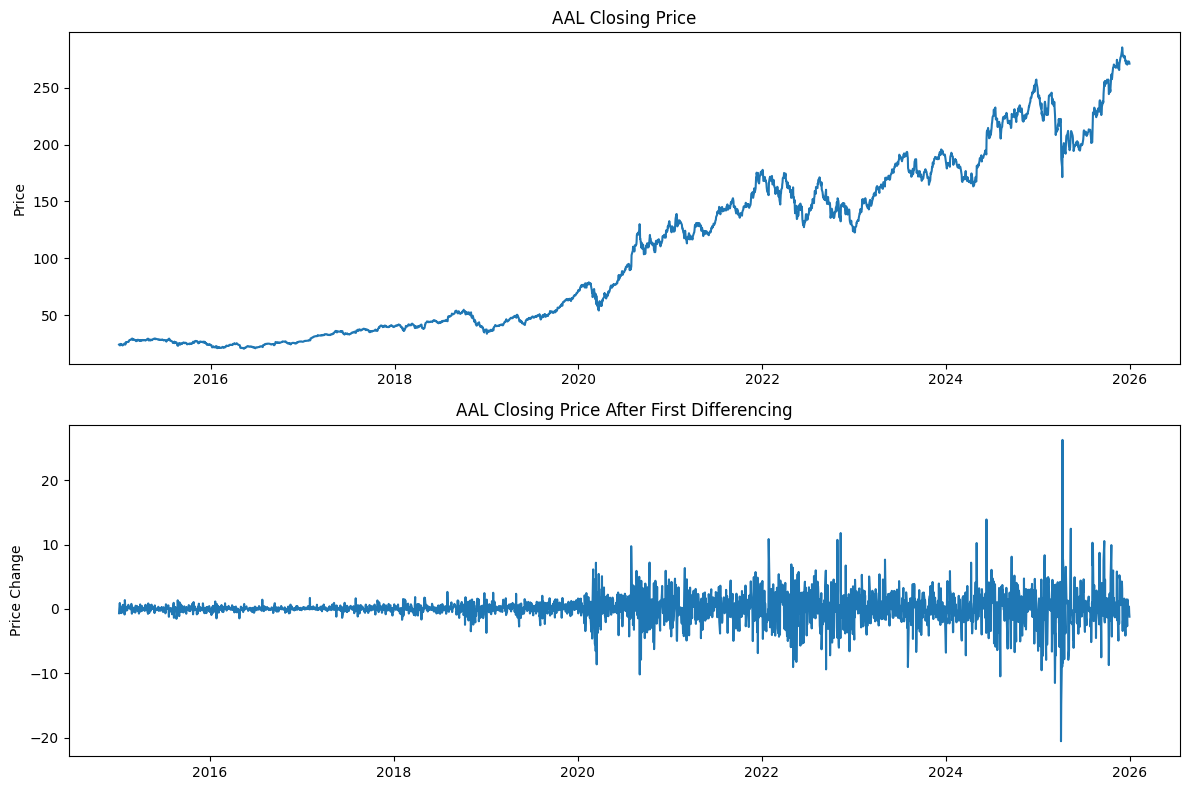

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(close)
ax[0].set_title("AAL Closing Price")
ax[0].set_ylabel("Price")

ax[1].plot(stationary_data)
ax[1].set_title("AAL Closing Price After First Differencing")
ax[1].set_ylabel("Price Change")

plt.tight_layout()
plt.show()